# Music Instrument Classification - Hybrid

## Setup

In [1]:
import os
import json
import numpy as np
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import seaborn as sns
from tensorflow.keras import layers, models, Model
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix
from tensorflow.keras.models import load_model

Utility function:

In [2]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None, title=''):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title(title)
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

Custom classes definition and indexing:

In [3]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

Loading features and labels:

In [4]:
X_stem_cqt = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
X_stem_mel = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))  # or cqt
y_stem = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))
X_mix_mel = np.load("extracted_mix_features/all_mels.npy")
X_mix_cqt = np.load("extracted_mix_features/all_cqts.npy")
y_mix = np.load("extracted_mix_features/all_labels.npy")

Showing the instrument distribution in the stems dataset:


Class distribution in the complete dataset:
    other_percussion:               9085 samples (13.2%)
    electric_bass:               6781 samples (9.8%)
    drum_set:               6300 samples (9.1%)
    piano:               5604 samples (8.1%)
    other_bowed_strings:               4946 samples (7.2%)
    clean_electric_guitar:               4790 samples (7.0%)
    synthesizer:               4711 samples (6.8%)
    other_plucked_strings:               3635 samples (5.3%)
    fx_and_processed:               3452 samples (5.0%)
    male_vocals:               3180 samples (4.6%)
    violin:               3010 samples (4.4%)
    distorted_electric_guitar:               2475 samples (3.6%)
    acoustic_guitar:               2452 samples (3.6%)
    female_singer:               2190 samples (3.2%)
    woodwinds:               1860 samples (2.7%)
    vocalists:               1565 samples (2.3%)
    reed_instruments:               1460 samples (2.1%)
    brass:               1383 samples (2

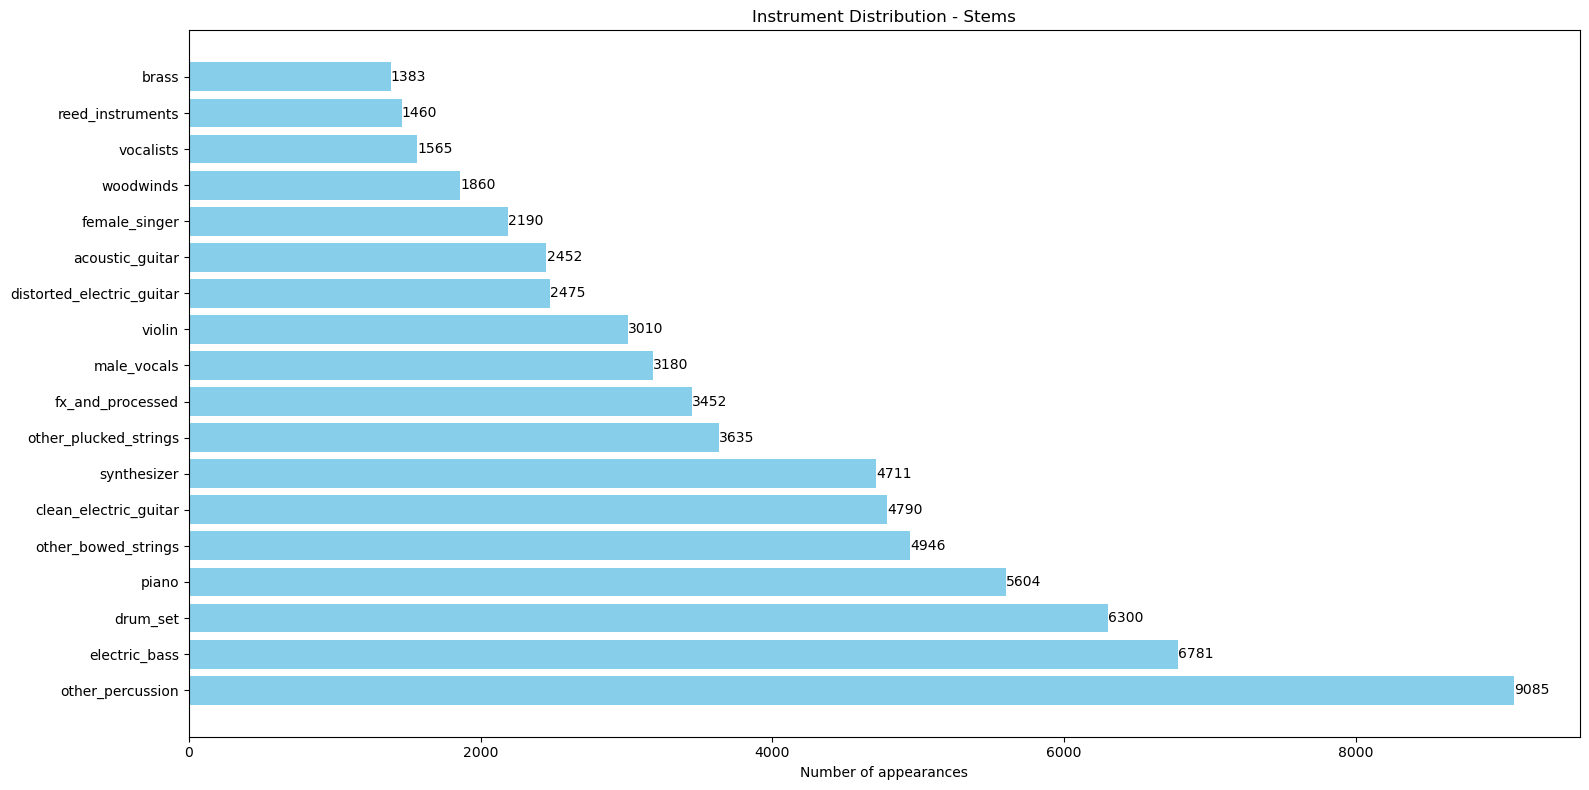


Dataset dimensions:
    Full data:                  (68879, 96, 130)
    Total number of samples:    68879
    Number of categories:       18


In [5]:
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_stem, return_counts=True)

# Create a dictionary: {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {category}:               {count} samples ({count / len(y_stem) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels), title='Instrument Distribution - Stems')

# Dataset summary
print(f"\nDataset dimensions:")
print(f"    Full data:                  {X_stem_mel.shape}")
print(f"    Total number of samples:    {len(y_stem)}")
print(f"    Number of categories:       {len(ordered_labels)}")

Showing the instrument distribution in the mixes dataset:


Class distribution in the complete dataset:
    electric_bass:               4100 samples (44.8%)
    drum_set:               3884 samples (42.4%)
    piano:               3395 samples (37.1%)
    other_percussion:               2597 samples (28.4%)
    clean_electric_guitar:               2402 samples (26.2%)
    other_plucked_strings:               1767 samples (19.3%)
    other_bowed_strings:               1760 samples (19.2%)
    male_vocals:               1733 samples (18.9%)
    synthesizer:               1558 samples (17.0%)
    acoustic_guitar:               1526 samples (16.7%)
    female_singer:               1330 samples (14.5%)
    fx_and_processed:               1108 samples (12.1%)
    distorted_electric_guitar:               1097 samples (12.0%)
    vocalists:               851 samples (9.3%)
    violin:               785 samples (8.6%)
    woodwinds:               750 samples (8.2%)
    reed_instruments:               750 samples (8.2%)
    brass:               653 sam

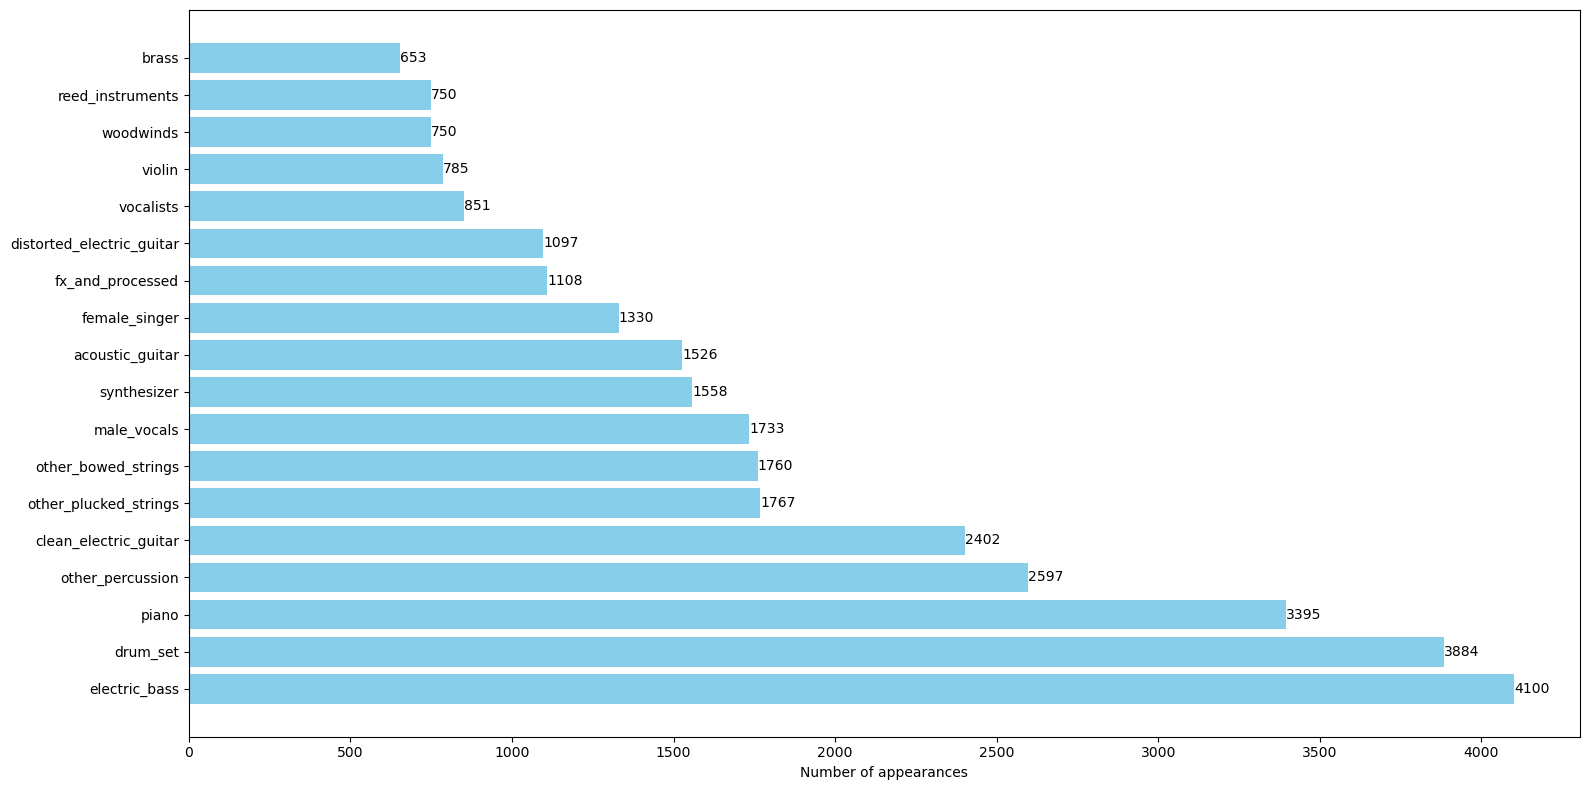


Dataset dimensions:
  X:                                (9154, 96, 130)
  y filtered (multi-hot):           (9154, 18)
  Total number of samples:          9154
  Number of current categories:     18


In [6]:
# Count the number of samples
class_counts = np.sum(y_mix, axis=0)

# Create a dictionary to hold the counts for each instrument category
category_counts = {label: int(count) for label, count in zip(ordered_labels, class_counts)}

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {category}:               {count} samples ({count / len(y_mix) * 100:.1f}%)")

# Plot the histogram of instrument frequencies
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

print(f"\nDataset dimensions:")
print(f"  X:                                {X_mix_cqt.shape}")
print(f"  y filtered (multi-hot):           {y_mix.shape}")
print(f"  Total number of samples:          {len(y_mix)}")
print(f"  Number of current categories:     {len(ordered_labels)}")

Data normalization:

In [7]:
mean_cqt = np.mean(X_mix_cqt)
std_cqt = np.std(X_mix_cqt)

mean_mel = np.mean(X_mix_mel)
std_mel = np.std(X_mix_mel)

X_stem_cqt = (X_stem_cqt - mean_cqt) / (std_cqt + 1e-6)
X_stem_mel = (X_stem_mel - mean_mel) / (std_mel + 1e-6)

X_mix_cqt = (X_mix_cqt - mean_cqt) / (std_cqt + 1e-6)
X_mix_mel = (X_mix_mel - mean_mel) / (std_mel + 1e-6)

Data splitting:

In [8]:
# Split into train, validation, and test sets for stem mel
X_temp, X_test_stem_mel, y_temp, y_test_stem = train_test_split(
    X_stem_mel, y_stem, test_size=0.1, random_state=42
)
X_train_stem_mel, X_val_stem_mel, y_train_stem, y_val_stem = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Split into train, validation, and test sets for mix mel
X_temp, X_test_mix_mel, y_temp, y_test_mix = train_test_split(
    X_mix_cqt, y_mix, test_size=0.1, random_state=42
)
X_train_mix_mel, X_val_mix_mel, y_train_mix, y_val_mix = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

## Model 1

We define an architecture using stems (softmax activation):

| Layer Type              | Details                                                        |
|:------------------------|:--------------------------------------------------------------|
| Input                   | Input shape: (96, 130, 1)                                      |
| Conv2D                  | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| Conv2D                  | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| GlobalAveragePooling2D  |                                                                |
| Dense                   | Units: **64**, Activation: relu                                |
| Dropout                 | Rate: 0.4                                                      |
| Dense                   | Units: 18, Activation: softmax (single-label output)           |

In [9]:
# Define the model for phase 1 (stems)
input_shape = [X_train_stem_mel.shape[1], X_train_stem_mel.shape[2], 1]
num_classes = len(ordered_labels)

model_phase1 = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model_phase1.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

# Print model summary
model_phase1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

Training the model and saving history and weights in the files `training_model_hybrid_stems.log` and `best_model_hybrid_stems.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [10]:
'''
# Callbacks for phase 1
callbacks_phase1 = [
    CSVLogger('training_model_hybrid_stems.log', append=False),
    EarlyStopping(monitor='val_loss', patience=25),
    ModelCheckpoint('best_model_hybrid_stems.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

# Train on stems
model_phase1.fit(
    X_train_stem_mel, y_train_stem,
    validation_data=(X_val_stem_mel, y_val_stem),
    epochs=200,
    batch_size=32,
    callbacks=callbacks_phase1
)
'''

"\n# Callbacks for phase 1\ncallbacks_phase1 = [\n    CSVLogger('training_model_hybrid_stems.log', append=False),\n    EarlyStopping(monitor='val_loss', patience=25),\n    ModelCheckpoint('best_model_hybrid_stems.h5', monitor='val_accuracy', save_best_only=True, verbose=1)\n]\n\n# Train on stems\nmodel_phase1.fit(\n    X_train_stem_mel, y_train_stem,\n    validation_data=(X_val_stem_mel, y_val_stem),\n    epochs=200,\n    batch_size=32,\n    callbacks=callbacks_phase1\n)\n"

Showing model 1 history:

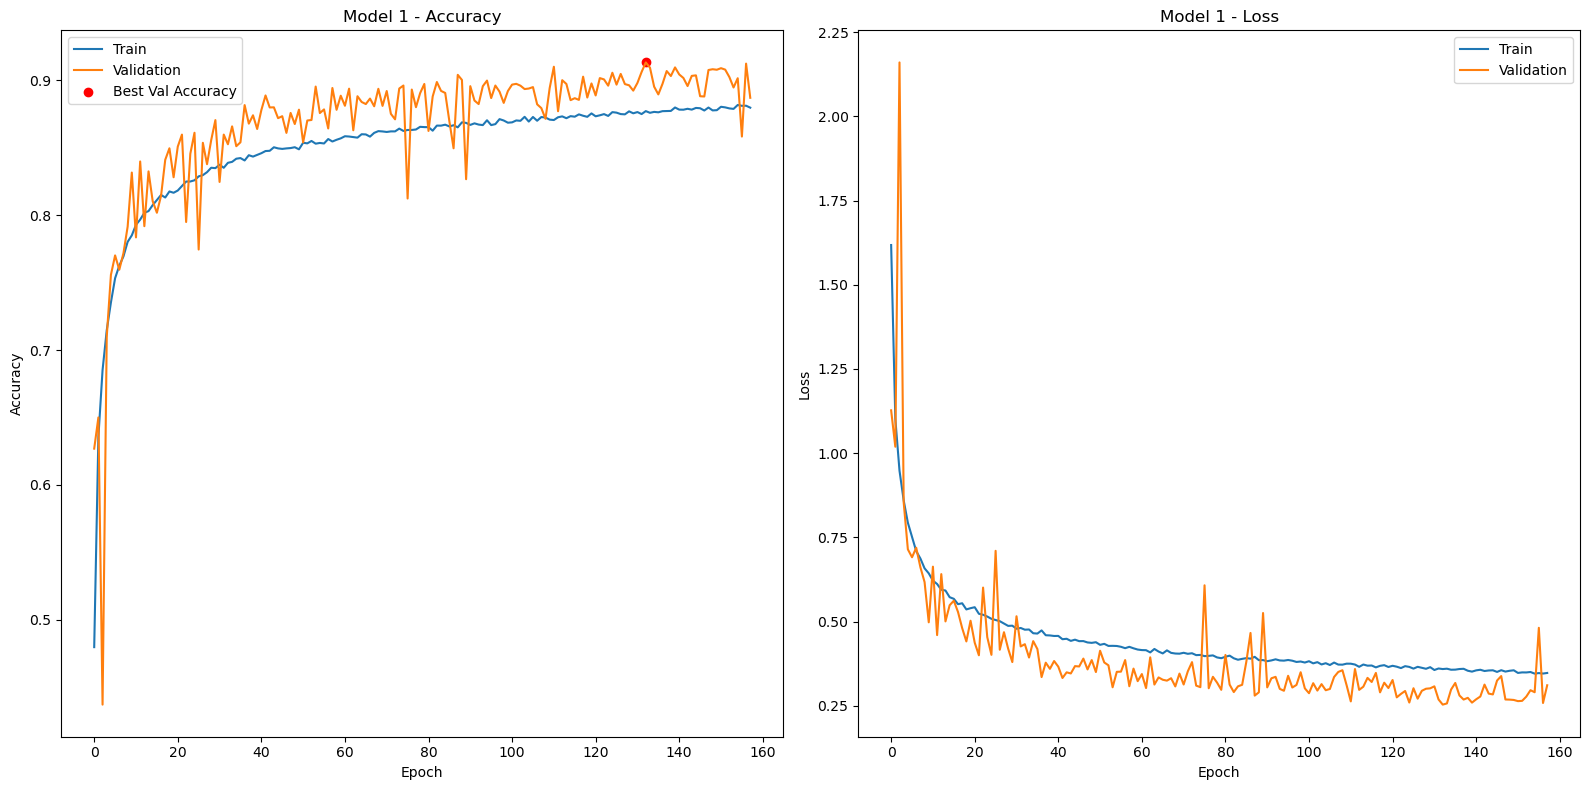

In [11]:
# History plot
log_df = pd.read_csv('training_model_hybrid_stems.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 1 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 1 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 1 confusion matrixes:

216/216 [==============================] - 0s 2ms/step


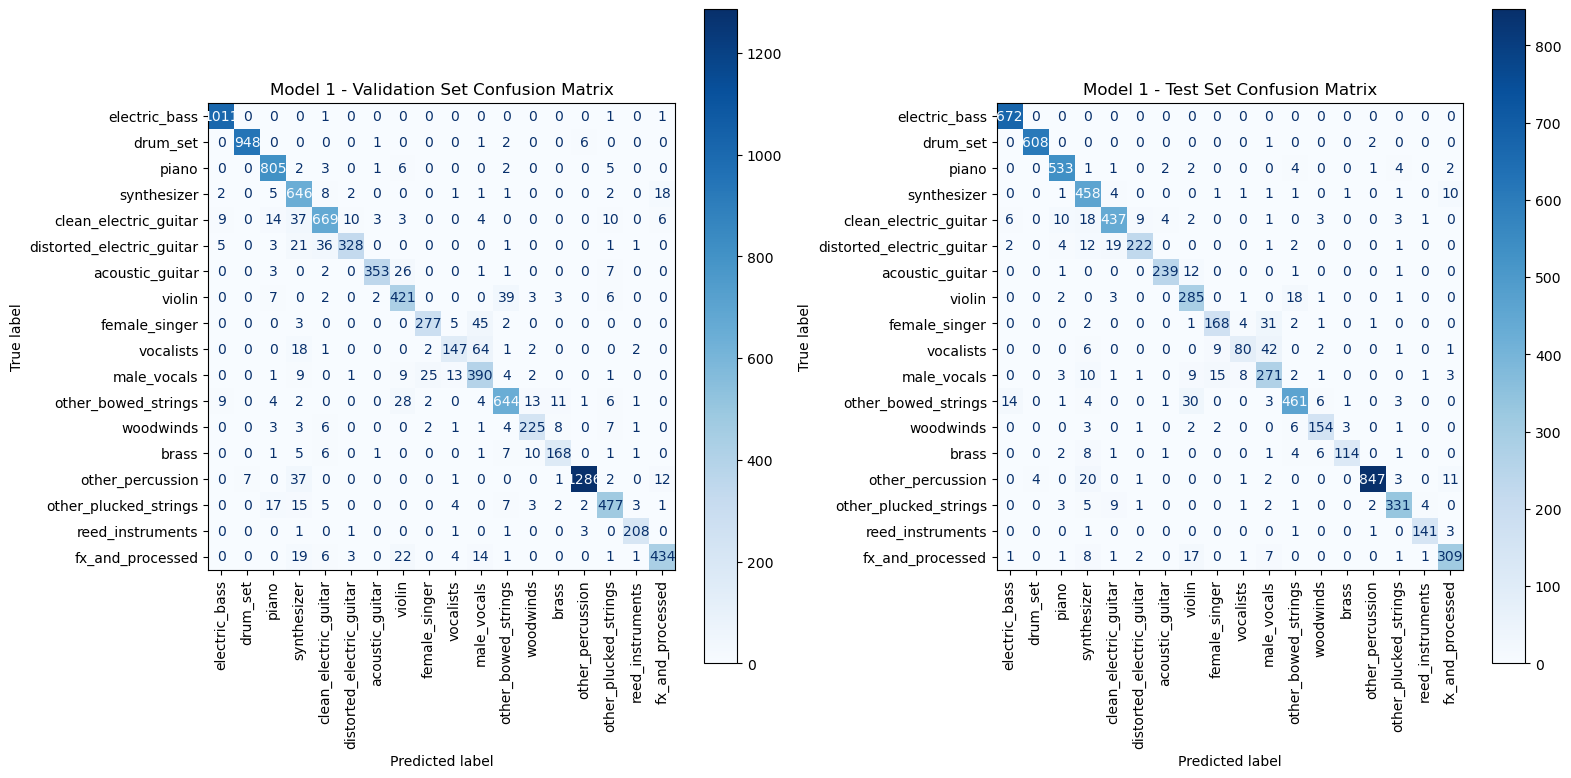

In [12]:
model_phase1.load_weights('best_model_hybrid_stems.h5')

# Generate predictions
y_val_pred = model_phase1.predict(X_val_stem_mel).argmax(axis=1)
y_test_pred = model_phase1.predict(X_test_stem_mel).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val_stem, y_val_pred)
test_cm = confusion_matrix(y_test_stem, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 1 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 1 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 1 classification reports:

In [13]:
# Classification reports for validation and test sets
print(classification_report(y_val_stem, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test_stem, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.98      1.00      0.99      1014
                 drum_set       0.99      0.99      0.99       958
                    piano       0.93      0.98      0.95       824
              synthesizer       0.79      0.94      0.86       686
    clean_electric_guitar       0.90      0.87      0.89       765
distorted_electric_guitar       0.95      0.83      0.89       396
          acoustic_guitar       0.98      0.90      0.94       393
                   violin       0.82      0.87      0.84       483
            female_singer       0.90      0.83      0.87       332
                vocalists       0.83      0.62      0.71       237
              male_vocals       0.74      0.86      0.80       455
      other_bowed_strings       0.90      0.89      0.89       725
                woodwinds       0.87      0.86      0.87       261
                    brass       0.87      0.84      0.85     

## Model 2

We define a similar architecture that works with mixes:

| Layer Type              | Details                                                        |
|:------------------------|:--------------------------------------------------------------|
| Input                   | Input shape: (96, 130, 1)                                      |
| Conv2D                  | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| Conv2D                  | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| GlobalAveragePooling2D  |                                                                |
| Dense                   | Units: **64**, Activation: relu                                    |
| Dropout                 | Rate: 0.4                                                      |
| Dense                   | Units: 18, Activation: sigmoid (multi-label output)            |

In [14]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extract layers and rebuild functionally
inputs = layers.Input(shape=input_shape)
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Exclude the last: Dense(softmax)
    x = layer(x)

# Add a new output layer for multilabel classification
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

# 2D-CNN model for phase 2 (multilabel classification)
model_phase2 = Model(inputs=inputs, outputs=outputs)

# Freeze the first N convolutional layers
N = 0
conv_layers_frozen = 0
for layer in model_phase2.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile the model
model_phase2.compile(optimizer='adam',
                     loss='binary_crossentropy',
                     metrics=['binary_accuracy'])

# Print model summary
model_phase2.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 96, 130, 1)]      0         
                                                                 
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128   

Training the model and saving history and weights in the files `training_model_hybrid_mix.log` and `best_model_hybrid_mix.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [15]:
'''
# Callbacks for phase 2
callbacks_phase2 = [
    CSVLogger('training_model_hybrid_mix.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix.h5', monitor='val_binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase2.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase2
)
'''

"\n# Callbacks for phase 2\ncallbacks_phase2 = [\n    CSVLogger('training_model_hybrid_mix.log', append=False),\n    EarlyStopping(monitor='val_loss', patience=50),\n    ModelCheckpoint('best_model_hybrid_mix.h5', monitor='val_binary_accuracy', save_best_only=True, verbose=1)\n]\n\n# Train on mixes\nhistory = model_phase2.fit(\n    X_train_mix_mel, y_train_mix,\n    validation_data=(X_val_mix_mel, y_val_mix),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks_phase2\n)\n"

Showing model 2 history:

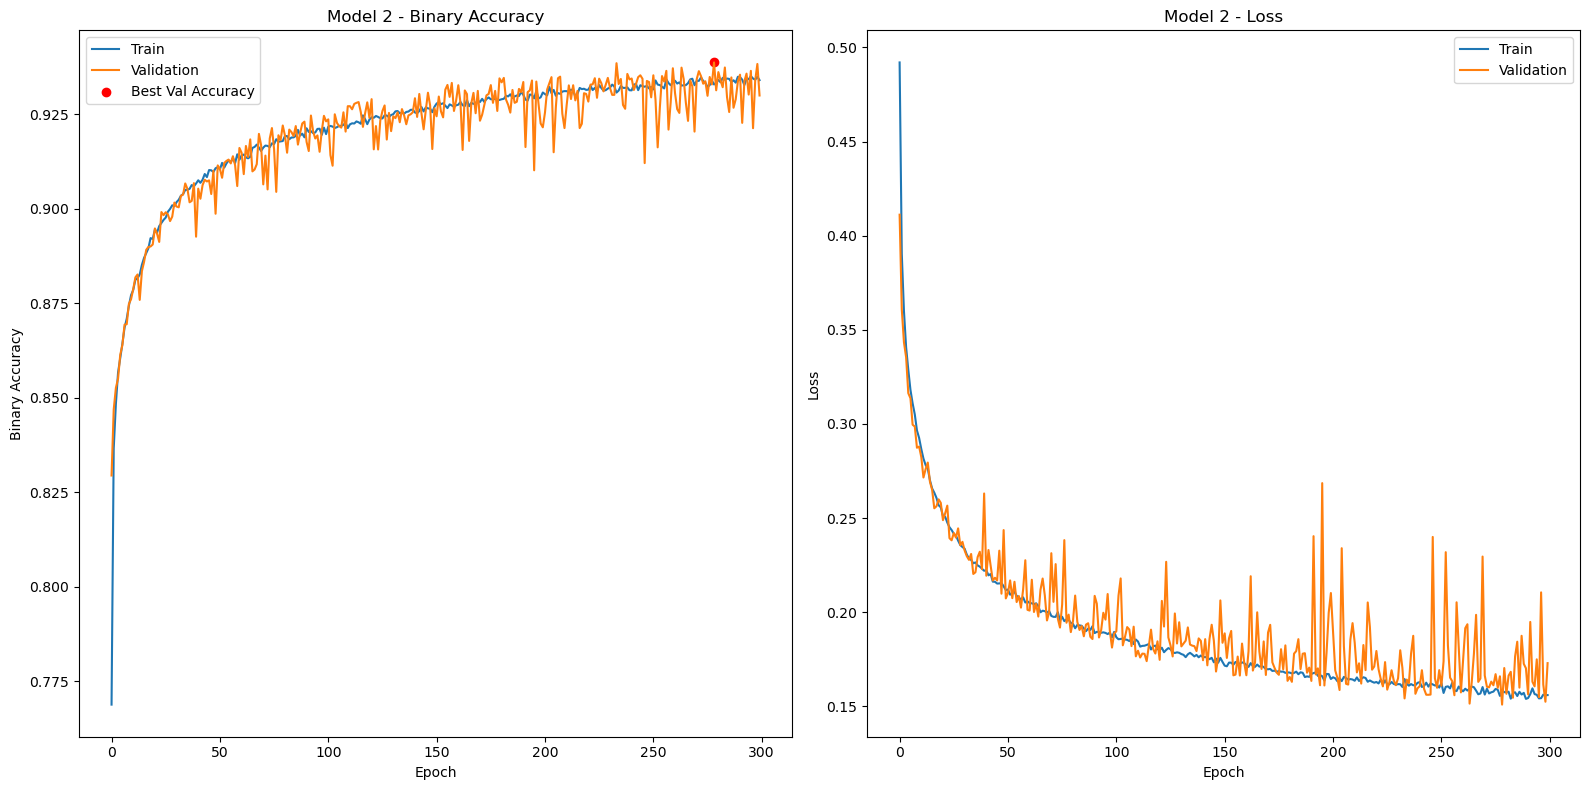

In [16]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 2 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 2 confusion matrixes:

29/29 [==============================] - 0s 4ms/step


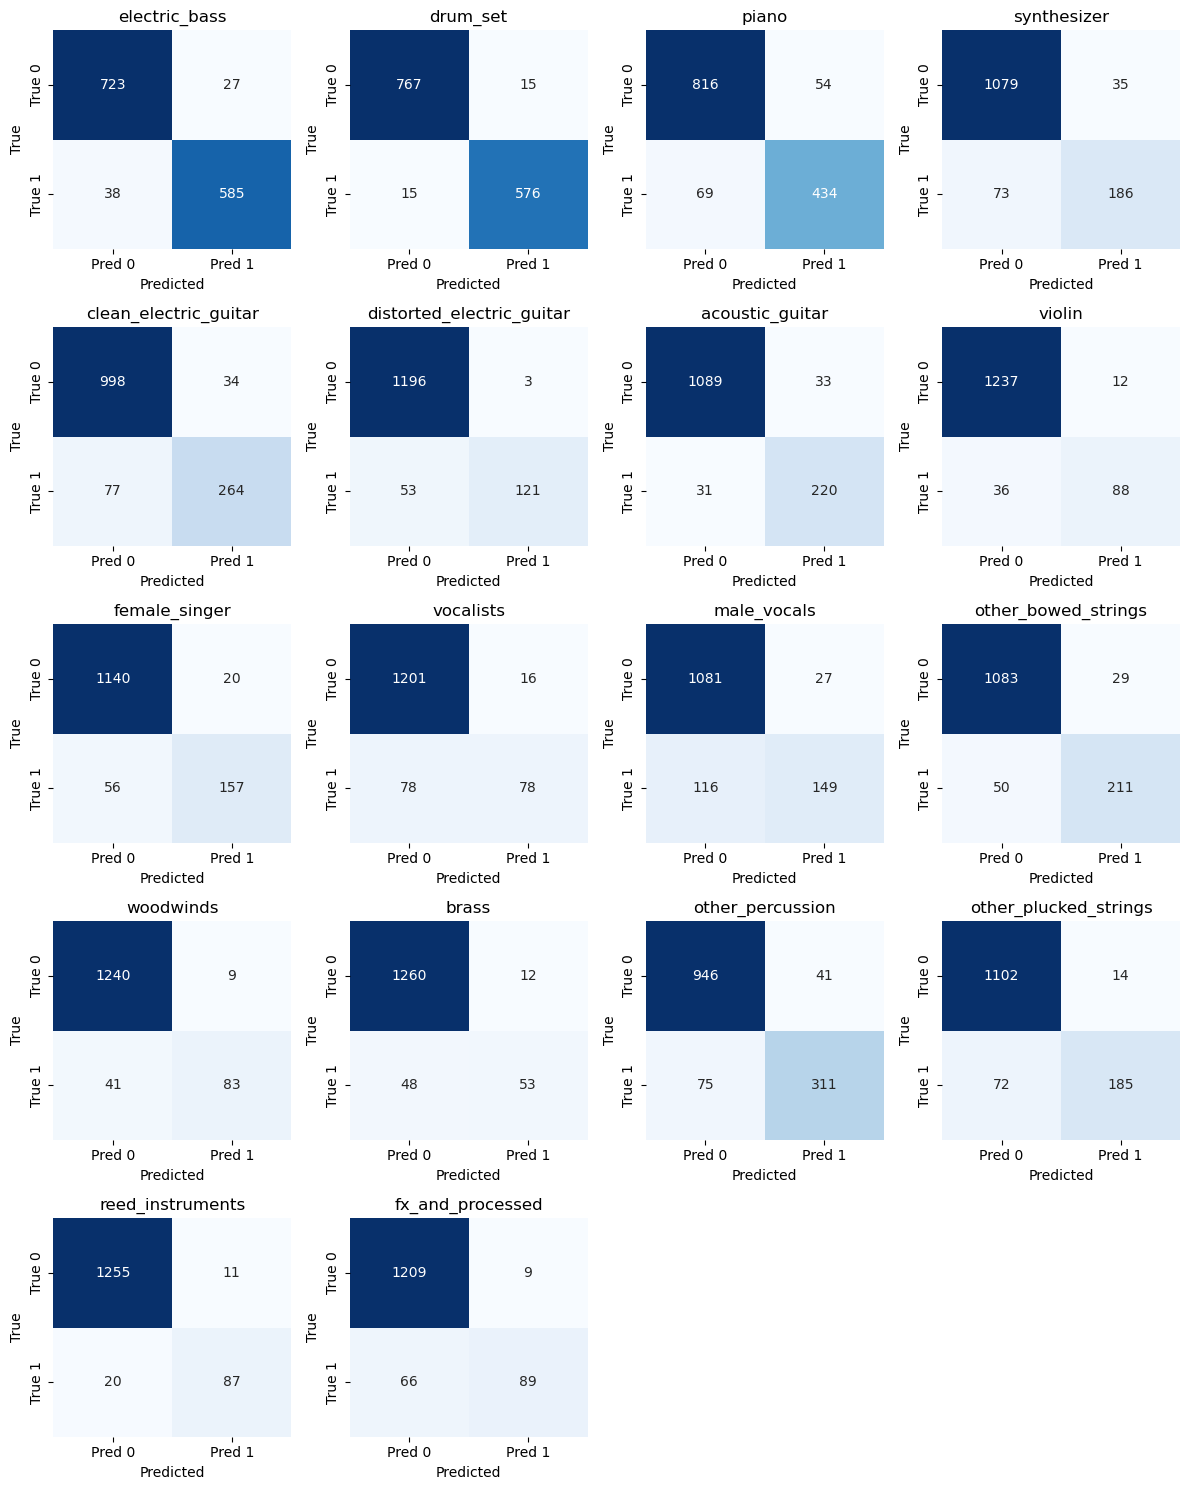

In [17]:
model_phase2.load_weights('best_model_hybrid_mix.h5')

# Predict probabilities
y_val_pred_prob = model_phase2.predict(X_val_mix_mel)
y_test_pred_prob = model_phase2.predict(X_test_mix_mel)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val_mix, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test_mix, y_test_pred)

# Plot
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 2 classification reports:

In [18]:
# Classification report for validation and test sets
print(classification_report(y_val_mix, y_val_pred))
print(classification_report(y_test_mix, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       623
           1       0.97      0.97      0.97       591
           2       0.89      0.86      0.88       503
           3       0.84      0.72      0.78       259
           4       0.89      0.77      0.83       341
           5       0.98      0.70      0.81       174
           6       0.87      0.88      0.87       251
           7       0.88      0.71      0.79       124
           8       0.89      0.74      0.81       213
           9       0.83      0.50      0.62       156
          10       0.85      0.56      0.68       265
          11       0.88      0.81      0.84       261
          12       0.90      0.67      0.77       124
          13       0.82      0.52      0.64       101
          14       0.88      0.81      0.84       386
          15       0.93      0.72      0.81       257
          16       0.89      0.81      0.85       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Model 3

We define a new model reusing the feature extraction layers from the best stem model and adapting it for multi-label classification on the mixes dataset:

| Layer Type              | Details                                                        |
|:------------------------|:--------------------------------------------------------------|
| Input                   | Input shape: (96, 130, 1)                                     |
| Conv2D                  | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| Conv2D                  | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization      |                                                                |
| MaxPooling2D            | Pool size: 2x2                                                |
| GlobalAveragePooling2D  |                                                                |
| Dense                   | Units: **64**, Activation: relu                               |
| Dropout                 | Rate: 0.4                                                     |
| Dense                   | Units: 18, Activation: sigmoid (multi-label output)           |

In [19]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extract layers and rebuild functionally
inputs = layers.Input(shape=input_shape)
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Exclude the last: Dense(softmax)
    x = layer(x)

# Add a new output layer for multilabel classification
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

# 2D-CNN model for phase 3 (multilabel classification)
model_phase3 = Model(inputs=inputs, outputs=outputs)

# Freeze the first N convolutional layers
N = 0
conv_layers_frozen = 0
for layer in model_phase3.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile the model
model_phase3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        'binary_accuracy'
    ]
)

# Print model summary
model_phase3.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 96, 130, 1)]      0         
                                                                 
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128 

Training the model and saving history and weights in the files `training_model_hybrid_mix_2.log` and `best_model_hybrid_mix_2.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [20]:
'''
# Callbacks for phase 3
callbacks_phase3 = [
    CSVLogger('training_model_hybrid_mix_2.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix_2.h5', monitor='binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase3.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase3
)
'''

"\n# Callbacks for phase 3\ncallbacks_phase3 = [\n    CSVLogger('training_model_hybrid_mix_2.log', append=False),\n    EarlyStopping(monitor='val_loss', patience=50),\n    ModelCheckpoint('best_model_hybrid_mix_2.h5', monitor='binary_accuracy', save_best_only=True, verbose=1)\n]\n\n# Train on mixes\nhistory = model_phase3.fit(\n    X_train_mix_mel, y_train_mix,\n    validation_data=(X_val_mix_mel, y_val_mix),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks_phase3\n)\n"

Showing model 3 history:

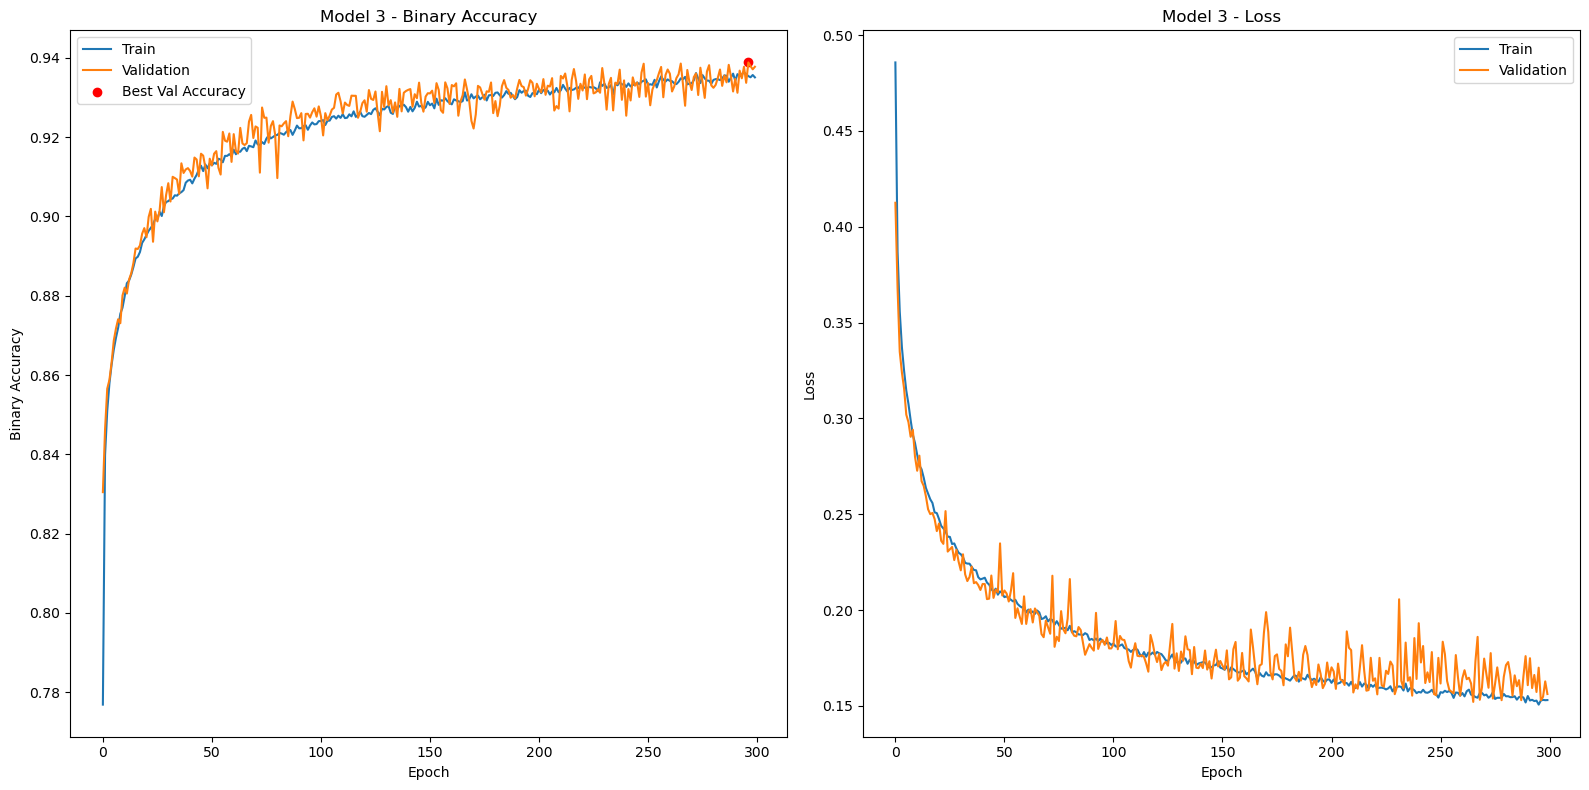

In [21]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix_2.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 3 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 3 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 3 confusion matrixes:

29/29 [==============================] - 0s 3ms/step


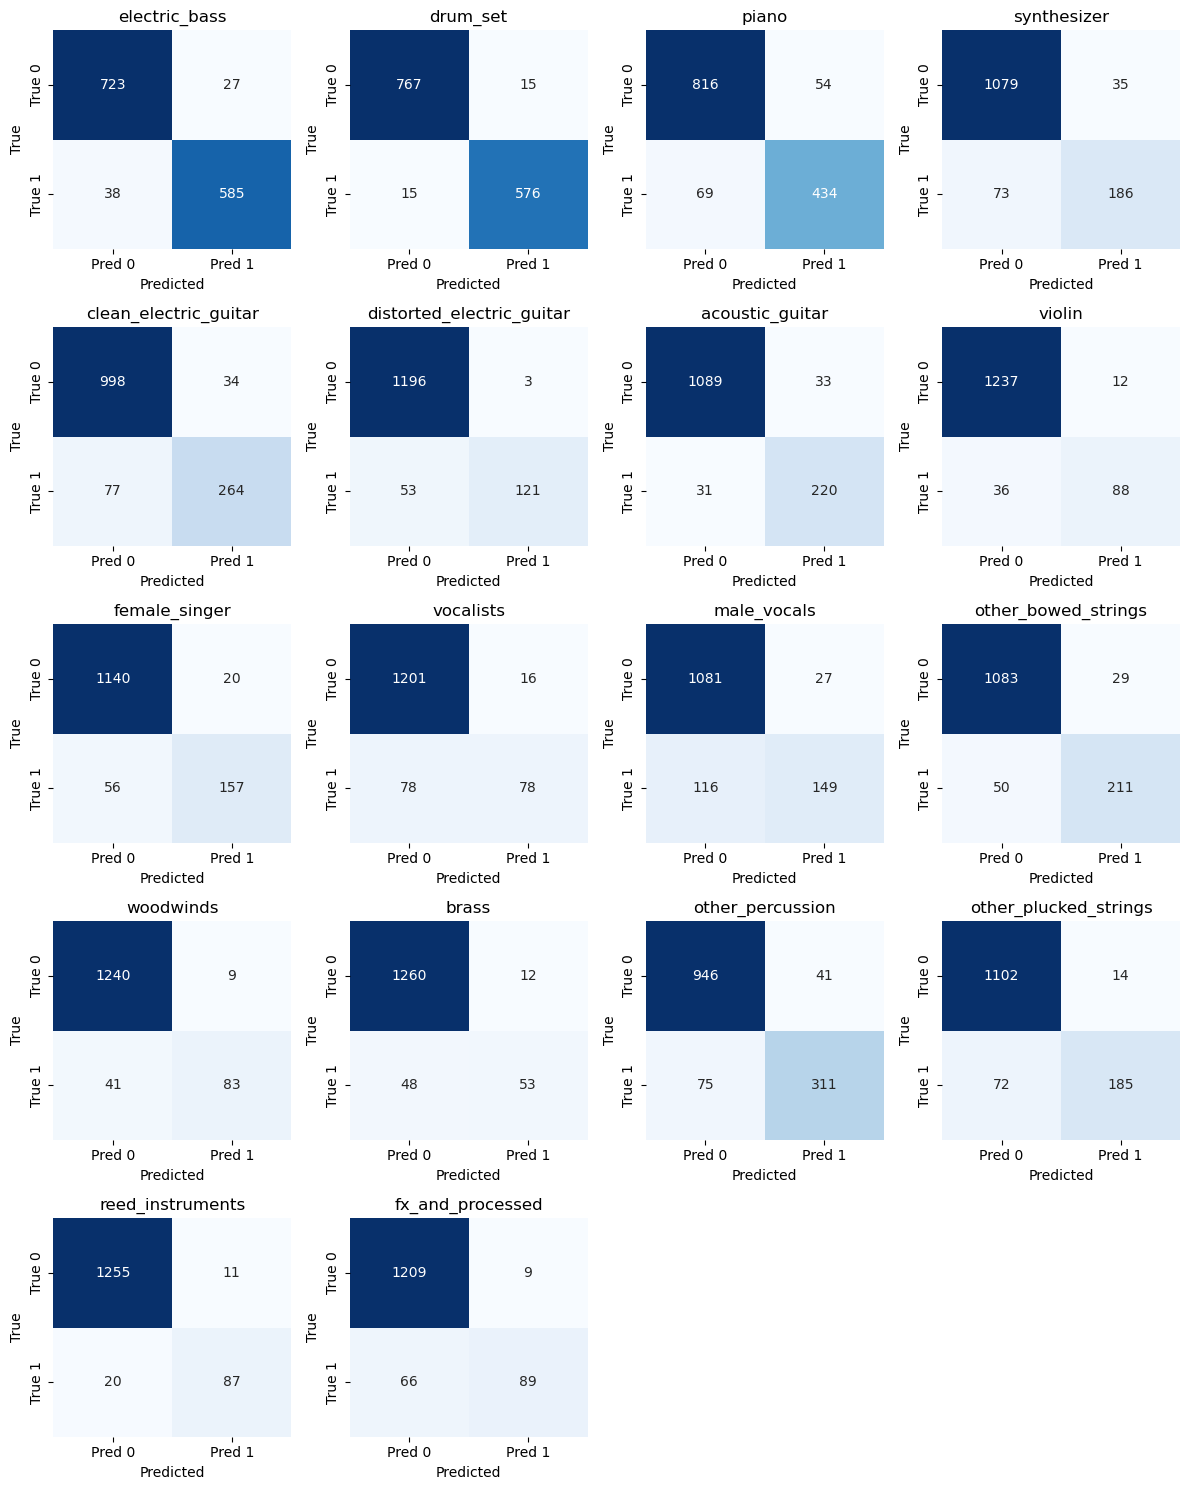

In [22]:
model_phase3.load_weights('best_model_hybrid_mix_2.h5')

# Predict probabilities
y_val_pred_prob = model_phase2.predict(X_val_mix_mel)
y_test_pred_prob = model_phase2.predict(X_test_mix_mel)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val_mix, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test_mix, y_test_pred)

# Plot
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 3 classification reports:

In [23]:
# Classification report for validation and test sets
print(classification_report(y_val_mix, y_val_pred))
print(classification_report(y_test_mix, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       623
           1       0.97      0.97      0.97       591
           2       0.89      0.86      0.88       503
           3       0.84      0.72      0.78       259
           4       0.89      0.77      0.83       341
           5       0.98      0.70      0.81       174
           6       0.87      0.88      0.87       251
           7       0.88      0.71      0.79       124
           8       0.89      0.74      0.81       213
           9       0.83      0.50      0.62       156
          10       0.85      0.56      0.68       265
          11       0.88      0.81      0.84       261
          12       0.90      0.67      0.77       124
          13       0.82      0.52      0.64       101
          14       0.88      0.81      0.84       386
          15       0.93      0.72      0.81       257
          16       0.89      0.81      0.85       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
